In [2]:
import sys

print(sys.executable)

c:\Users\redba\OneDrive\Documents\developer\ICU\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np

In [4]:
DATA_PATH = "../data/raw/Food_Inspections_20261005.csv"

In [5]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (316703, 17)


In [6]:
print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type', 'Risk', 'Address', 'City', 'State', 'Zip', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Latitude', 'Longitude', 'Location']


In [7]:
df.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,2643646,FISKE,FISKE,3240691.0,School,Risk 1 (High),6020 S Langley (700E),CHICAGO,IL,60637.0,10/02/2026,Canvass,Pass,51. PLUMBING INSTALLED; PROPER BACKFLOW DEVICE...,41.785171,-87.608669,"(41.78517098599124, -87.60866926592186)"
1,2643653,KIDDIE TREASURE HOUSE,KREATIVE KIDZ ACADEMY V,2791311.0,Daycare Above and Under 2 Years,Risk 1 (High),4748 S ASHLAND AVE,CHICAGO,IL,60609.0,10/02/2026,Canvass,Pass w/ Conditions,40. PERSONAL CLEANLINESS - Comments: Food hand...,41.807154,-87.665079,"(41.80715363270352, -87.66507931081918)"
2,2643672,K'S POPPIN GOURMET POPCORN LLC,K'S POPPIN GOURMET POPCORN,2948398.0,Restaurant,Risk 2 (Medium),4700 S PRAIRIE AVE,CHICAGO,IL,60615.0,10/02/2026,Complaint,Pass,NaN,41.809242,-87.619737,"(41.809242496494626, -87.61973680173412)"
3,2643656,ST. SABINA ACADEMY,ST. SABINA ACADEMY,2247641.0,School,Risk 1 (High),7801 S THROOP ST,CHICAGO,IL,60620.0,10/02/2026,Canvass,Pass,NaN,41.752251,-87.655245,"(41.752251353988434, -87.65524497504356)"
4,2643668,THE LITTLE SCHOLARS CLUB,THE LITTLE SCHOLARS CLUB,2216135.0,Daycare Above and Under 2 Years,Risk 1 (High),5752-5754 S PULASKI RD,CHICAGO,IL,60629.0,10/02/2026,Canvass,Pass,"55. PHYSICAL FACILITIES INSTALLED, MAINTAINED ...",41.787989,-87.723161,"(41.78798915982268, -87.72316081027732)"


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 316703 entries, 0 to 316702
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    316703 non-null  int64  
 1   DBA Name         316703 non-null  str    
 2   AKA Name         314277 non-null  str    
 3   License #        316684 non-null  float64
 4   Facility Type    311344 non-null  str    
 5   Risk             316616 non-null  str    
 6   Address          316703 non-null  str    
 7   City             316521 non-null  str    
 8   State            316627 non-null  str    
 9   Zip              316661 non-null  float64
 10  Inspection Date  316703 non-null  str    
 11  Inspection Type  316702 non-null  str    
 12  Results          316703 non-null  str    
 13  Violations       227378 non-null  str    
 14  Latitude         315645 non-null  float64
 15  Longitude        315645 non-null  float64
 16  Location         315645 non-null  str    
dtypes:

In [9]:
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values.sort_values(ascending=False))

Missing values per column:
Violations         89325
Facility Type       5359
AKA Name            2426
Longitude           1058
Location            1058
Latitude            1058
City                 182
Risk                  87
State                 76
Zip                   42
License #             19
Inspection Type        1
Inspection ID          0
Address                0
DBA Name               0
Results                0
Inspection Date        0
dtype: int64


In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing percentage per column:")
print(missing_percentage.sort_values(ascending=False).round(2))

Missing percentage per column:
Violations         28.20
Facility Type       1.69
AKA Name            0.77
Longitude           0.33
Location            0.33
Latitude            0.33
City                0.06
Risk                0.03
State               0.02
Zip                 0.01
License #           0.01
Inspection Type     0.00
Inspection ID       0.00
Address             0.00
DBA Name            0.00
Results             0.00
Inspection Date     0.00
dtype: float64


In [11]:
duplicate_inspection_ids = df["Inspection ID"].duplicated().sum()

print("Duplicate Inspection IDs:", duplicate_inspection_ids)

Duplicate Inspection IDs: 0


In [12]:
duplicate_rows = df.duplicated().sum()

print("Completely duplicated rows:", duplicate_rows)

Completely duplicated rows: 0


In [13]:
df["Inspection Date"] = pd.to_datetime(
    df["Inspection Date"],
    errors="coerce"
)

print("Earliest inspection:", df["Inspection Date"].min())
print("Latest inspection:", df["Inspection Date"].max())
print("Invalid dates:", df["Inspection Date"].isna().sum())

Earliest inspection: 2010-01-04 00:00:00
Latest inspection: 2026-10-02 00:00:00
Invalid dates: 0


In [14]:
result_counts = df["Results"].value_counts(dropna=False)

print("Inspection result categories:")
print(result_counts)

Inspection result categories:
Results
Pass                    163949
Fail                     60968
Pass w/ Conditions       46963
Out of Business          25919
No Entry                 14189
Not Ready                 4619
Business Not Located        96
Name: count, dtype: int64


In [15]:
result_percentage = (
    df["Results"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("Inspection result percentages:")
print(result_percentage)

Inspection result percentages:
Results
Pass                    51.77
Fail                    19.25
Pass w/ Conditions      14.83
Out of Business          8.18
No Entry                 4.48
Not Ready                1.46
Business Not Located     0.03
Name: proportion, dtype: float64


In [16]:
risk_counts = df["Risk"].value_counts(dropna=False)

print("Risk categories:")
print(risk_counts)

Risk categories:
Risk
Risk 1 (High)      235769
Risk 2 (Medium)     56173
Risk 3 (Low)        24586
All                    88
NaN                    87
Name: count, dtype: int64


In [17]:
inspection_type_counts = df["Inspection Type"].value_counts(dropna=False)

print("Inspection types:")
print(inspection_type_counts)

Inspection types:
Inspection Type
Canvass                          163530
License                           42469
Canvass Re-Inspection             35279
Complaint                         30019
License Re-Inspection             12841
                                  ...  
TASK FORCE NOT READY                  1
LIQOUR TASK FORCE NOT READY           1
POSSIBLE FBI                          1
Kids Cafe'                            1
TASK FORCE PACKAGE GOODS 1474         1
Name: count, Length: 111, dtype: int64


In [18]:
facility_counts = df["Facility Type"].value_counts(dropna=False)

print("Number of unique facility types:", df["Facility Type"].nunique(dropna=False))
print("\nTop 20 facility types:")
print(facility_counts.head(20))

Number of unique facility types: 528

Top 20 facility types:
Facility Type
Restaurant                         214845
Grocery Store                       37963
School                              19825
Children's Services Facility         7802
NaN                                  5359
Bakery                               4553
Daycare Above and Under 2 Years      4193
Daycare (2 - 6 Years)                3266
Long Term Care                       2435
Catering                             1958
Liquor                               1365
Mobile Food Preparer                 1315
Hospital                              987
Mobile Food Dispenser                 967
Golden Diner                          894
Daycare Combo 1586                    626
Wholesale                             593
Shared Kitchen User (Long Term)       497
TAVERN                                435
Special Event                         384
Name: count, dtype: int64


In [19]:
restaurant_df = df[df["Facility Type"] == "Restaurant"].copy()

print("Restaurant records:", len(restaurant_df))
print("Percentage of total dataset:", round(len(restaurant_df) / len(df) * 100, 2), "%")

Restaurant records: 214845
Percentage of total dataset: 67.84 %


In [20]:
print("Unique restaurant licenses:", restaurant_df["License #"].nunique())
print("Missing restaurant licenses:", restaurant_df["License #"].isna().sum())

Unique restaurant licenses: 27857
Missing restaurant licenses: 1


In [21]:
inspection_count_per_restaurant = (
    restaurant_df.groupby("License #")["Inspection ID"]
    .count()
    .sort_values(ascending=False)
)

print("Inspection count per restaurant:")
print(inspection_count_per_restaurant.describe())

Inspection count per restaurant:
count    27857.000000
mean         7.712388
std          7.734687
min          1.000000
25%          2.000000
50%          5.000000
75%         11.000000
max        208.000000
Name: Inspection ID, dtype: float64


In [22]:
restaurants_with_2plus = (inspection_count_per_restaurant >= 2).sum()
restaurants_with_3plus = (inspection_count_per_restaurant >= 3).sum()

print("Restaurants with at least 2 inspections:", restaurants_with_2plus)
print("Restaurants with at least 3 inspections:", restaurants_with_3plus)

print(
    "Percentage with 2+ inspections:",
    round(restaurants_with_2plus / len(inspection_count_per_restaurant) * 100, 2),
    "%"
)

print(
    "Percentage with 3+ inspections:",
    round(restaurants_with_3plus / len(inspection_count_per_restaurant) * 100, 2),
    "%"
)

Restaurants with at least 2 inspections: 23183
Restaurants with at least 3 inspections: 19369
Percentage with 2+ inspections: 83.22 %
Percentage with 3+ inspections: 69.53 %


In [23]:
license_name_counts = (
    restaurant_df.groupby("License #")["DBA Name"]
    .nunique()
)

print("Licenses with multiple DBA names:", (license_name_counts > 1).sum())
print("Maximum DBA names for one license:", license_name_counts.max())

Licenses with multiple DBA names: 844
Maximum DBA names for one license: 102


In [24]:
license_name_summary = (
    restaurant_df.groupby("License #")["DBA Name"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 licenses by number of DBA names:")
print(license_name_summary.head(10))

Top 10 licenses by number of DBA names:
License #
0.0          102
14616.0        6
1354323.0      5
1514802.0      4
2220904.0      4
2147539.0      4
12141.0        4
2334563.0      3
1270965.0      3
51050.0        3
Name: DBA Name, dtype: int64


In [25]:
zero_license_count = (restaurant_df["License #"] == 0).sum()

print("Restaurant records with License # = 0:", zero_license_count)

Restaurant records with License # = 0: 208


In [26]:
license_14616 = (
    restaurant_df[restaurant_df["License #"] == 14616]
    [["License #", "DBA Name", "AKA Name", "Address", "City", "Inspection Date"]]
    .sort_values("Inspection Date")
)

license_14616

,License #,DBA Name,AKA Name,Address,City,Inspection Date
312863,14616.0,ILLINOIS SPORTSERVICE INC.,LA RUSSA'S CORNER STAND #154,333 W 35TH ST,CHICAGO,2010-03-25
312770,14616.0,ILLINOIS SPORTSERVICE INC,OZZIES AND HAROLD'S ALL-STAR STAND #152,333 W 35TH ST,CHICAGO,2010-03-25
312777,14616.0,ILLINOIS SPORTSERVICE INC,GROUNDS KEEPER/WINNING UGLY IS SWEET (#143/144),333 W 35TH ST,CHICAGO,2010-03-25
312778,14616.0,ILLINOIS SPORTSERVICE INC,DIPPING DOTS (SEC. #132),333 W 35TH ST,CHICAGO,2010-03-25
312800,14616.0,ILLINOIS SPORTSERVICE INC.,LUKE APPLING'S ALL STAR STAND #510,333 W 35TH ST,CHICAGO,2010-03-25
312810,14616.0,ILLINOIS SPORTSERVICE INC.,SHOELESS JOE/CONNIE'S PIZZA STAND #101-102,333 W 35TH ST,CHICAGO,2010-03-25
312826,14616.0,ILLINOIS SPORTSERVICE INC,KITTIES BRATS & SAUSAGE 4 (534),333 W 35TH ST,CHICAGO,2010-03-25
312791,14616.0,ILLINOIS SPORTSERVICE INC,GO GO WHITE SOX,333 W 35 ST,CHICAGO,2010-03-25
312836,14616.0,ILLINOIS SPORTSERVICE INC,BLACK JACK ALL STAR AND PIZZA STAND #163,333 W 35TH ST,CHICAGO,2010-03-25
312839,14616.0,"ILLINOIS SPORTSERVICE, INC.",MINNIE'S ALL-STAR STAND #522,333 W 35TH ST,CHICAGO,2010-03-25


In [27]:
license_address_counts = (
    restaurant_df.groupby("License #")["Address"]
    .nunique()
)

print("Licenses with multiple addresses:", (license_address_counts > 1).sum())
print("Maximum addresses for one license:", license_address_counts.max())

Licenses with multiple addresses: 11546
Maximum addresses for one license: 118


In [28]:
license_address_pairs = (
    restaurant_df
    .groupby(["License #", "Address"])["Inspection ID"]
    .count()
    .sort_values(ascending=False)
)

print("Unique License + Address combinations:", len(license_address_pairs))

print("\nInspection count per License + Address:")
print(license_address_pairs.describe())

Unique License + Address combinations: 39604

Inspection count per License + Address:
count    39604.000000
mean         5.424806
std          5.578149
min          1.000000
25%          2.000000
50%          3.000000
75%          7.000000
max        186.000000
Name: Inspection ID, dtype: float64


In [29]:
pair_name_counts = (
    restaurant_df
    .groupby(["License #", "Address"])["DBA Name"]
    .nunique()
)

print("License + Address pairs with multiple DBA names:",
      (pair_name_counts > 1).sum())

print("Maximum DBA names for one License + Address:",
      pair_name_counts.max())

License + Address pairs with multiple DBA names: 983
Maximum DBA names for one License + Address: 6


In [30]:
address_license_counts = (
    restaurant_df
    .groupby("Address")["License #"]
    .nunique()
    .sort_values(ascending=False)
)

print("Addresses with multiple licenses:",
      (address_license_counts > 1).sum())

print("Maximum licenses at one address:",
      address_license_counts.max())

Addresses with multiple licenses: 9080
Maximum licenses at one address: 235


In [31]:
pair_inspection_counts = (
    restaurant_df
    .groupby(["License #", "Address"])["Inspection ID"]
    .count()
)

pairs_with_2plus = (pair_inspection_counts >= 2).sum()
pairs_with_3plus = (pair_inspection_counts >= 3).sum()

print("Restaurant-location pairs:", len(pair_inspection_counts))
print("Pairs with 2+ inspections:", pairs_with_2plus)
print("Pairs with 3+ inspections:", pairs_with_3plus)

print(
    "Percentage with 2+ inspections:",
    round(pairs_with_2plus / len(pair_inspection_counts) * 100, 2),
    "%"
)

print(
    "Percentage with 3+ inspections:",
    round(pairs_with_3plus / len(pair_inspection_counts) * 100, 2),
    "%"
)

Restaurant-location pairs: 39604
Pairs with 2+ inspections: 30564
Pairs with 3+ inspections: 23881
Percentage with 2+ inspections: 77.17 %
Percentage with 3+ inspections: 60.3 %


In [32]:
restaurant_history = (
    restaurant_df
    .sort_values(["License #", "Address", "Inspection Date"])
    .copy()
)

restaurant_history["days_since_previous"] = (
    restaurant_history
    .groupby(["License #", "Address"])["Inspection Date"]
    .diff()
    .dt.days
)

print("Inspection intervals:")
print(
    restaurant_history["days_since_previous"]
    .describe()
)

Inspection intervals:
count    175240.000000
mean        300.248636
std         373.511653
min           0.000000
25%          21.000000
50%         239.000000
75%         395.000000
max        5578.000000
Name: days_since_previous, dtype: float64


In [33]:
zero_day_intervals = (
    restaurant_history["days_since_previous"] == 0
).sum()

total_intervals = restaurant_history["days_since_previous"].notna().sum()

print("Same-day inspection intervals:", zero_day_intervals)
print(
    "Percentage of intervals that are same-day:",
    round(zero_day_intervals / total_intervals * 100, 2),
    "%"
)

Same-day inspection intervals: 1451
Percentage of intervals that are same-day: 0.83 %


In [34]:
violation_available = restaurant_df["Violations"].notna()

print("Restaurant records:", len(restaurant_df))
print("Records with violations:", violation_available.sum())
print("Records without violations:", (~violation_available).sum())

print(
    "Percentage with violations:",
    round(violation_available.mean() * 100, 2),
    "%"
)

Restaurant records: 214845
Records with violations: 157277
Records without violations: 57568
Percentage with violations: 73.2 %


In [35]:
violation_status = (
    restaurant_df
    .assign(
        violation_status=restaurant_df["Violations"]
        .notna()
        .map({True: "Violations recorded", False: "No violation text"})
    )
    .groupby(["violation_status", "Results"])
    .size()
    .unstack(fill_value=0)
)

print(violation_status)

Results              Business Not Located   Fail  No Entry  Not Ready  \
violation_status                                                        
No violation text                      30   2249     11426       2965   
Violations recorded                     0  37777       585         44   

Results              Out of Business   Pass  Pass w/ Conditions  
violation_status                                                 
No violation text              15129  25016                 753  
Violations recorded               31  84316               34524  


In [36]:
sample_violations = (
    restaurant_df["Violations"]
    .dropna()
    .sample(5, random_state=42)
)

for i, violation in enumerate(sample_violations, start=1):
    print(f"\n--- Example {i} ---")
    print(violation)


--- Example 1 ---
2. FACILITIES TO MAINTAIN PROPER TEMPERATURE - Comments: REFRIGERATED PREP TABLE NOT MAINTAINING ADEQUATE TEMPERATURE, AIR TEMP-43.7-MUST HAVE UNIT REPAIRED , IT MUST MAINTAIN AN INTERNAL TEMPERATURE OF 40 DEGREES OR BELOW /- 2 DEGREES | 18. NO EVIDENCE OF RODENT OR INSECT OUTER OPENINGS PROTECTED/RODENT PROOFED, A WRITTEN LOG SHALL BE MAINTAINED AVAILABLE TO THE INSPECTORS - Comments: PEST CONTROL LOG BOOK DOES NOT HAVE STATE LICENSE OR LICENSE NUMBER BEGINNING WITH 051-MUST PROVIDE

--- Example 2 ---
10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: OBSERVED NO COLD WATER PROVIDED AT THE EXPOSED HAND WASHING SINK IN THE FOOD PREP AREA.  THE SINK HAS SEPARATE HOT AND COLD WATER HANDLES AND THE HOT WATER AT THE SINK WAS ABOVE 120F.  MANAGEMENT INSTRUCTED TO REPAIR AND PROVIDE COLD WATER AT THE EXPOSED HAND WASHING SINK SO THAT THE SINK CAN BE USED FOR HAND WASHING.  PRIORITY FOUNDATION 7-38-030(C).  CITATION ISSUED. | 40. PERSONAL CLEANLINES

In [37]:
violation_entries = (
    restaurant_df["Violations"]
    .dropna()
    .str.split("|")
    .explode()
    .str.strip()
)

print("Total individual violation entries:", len(violation_entries))
print("Unique violation entries:", violation_entries.nunique())

print("\nSample parsed entries:")
print(violation_entries.head())

Total individual violation entries: 740530
Unique violation entries: 604787

Sample parsed entries:
13    39. CONTAMINATION PREVENTED DURING FOOD PREPAR...
13    47. FOOD & NON-FOOD CONTACT SURFACES CLEANABLE...
13    51. PLUMBING INSTALLED; PROPER BACKFLOW DEVICE...
13    55. PHYSICAL FACILITIES INSTALLED, MAINTAINED ...
13    55. PHYSICAL FACILITIES INSTALLED, MAINTAINED ...
Name: Violations, dtype: str


In [38]:
violation_numbers = (
    violation_entries
    .str.extract(r"^(\d+)\.", expand=False)
)

print("Violation entries:", len(violation_entries))
print("Entries with extracted violation number:", violation_numbers.notna().sum())
print("Entries without a violation number:", violation_numbers.isna().sum())

print("\nMost common violation numbers:")
print(violation_numbers.value_counts().head(20))

Violation entries: 740530
Entries with extracted violation number: 740530
Entries without a violation number: 0

Most common violation numbers:
Violations
55    58285
38    51225
33    50064
34    49216
35    44124
32    40649
47    30163
41    26454
36    24206
49    23732
3     21034
51    19756
10    19650
58    19242
56    18167
37    15669
40    15278
30    13668
5     12796
2     12649
Name: count, dtype: int64


In [39]:
violation_frequency = (
    violation_numbers
    .value_counts()
    .rename_axis("Violation Number")
    .reset_index(name="Count")
)

violation_frequency["Percentage"] = (
    violation_frequency["Count"]
    / violation_frequency["Count"].sum()
    * 100
)

violation_frequency["Cumulative Percentage"] = (
    violation_frequency["Percentage"].cumsum()
)

print("Number of unique violation types:", len(violation_frequency))

print("\nTop 20 violation types:")
print(violation_frequency.head(20))

Number of unique violation types: 65

Top 20 violation types:
   Violation Number  Count  Percentage  Cumulative Percentage
0                55  58285    7.870714               7.870714
1                38  51225    6.917343              14.788057
2                33  50064    6.760563              21.548621
3                34  49216    6.646051              28.194671
4                35  44124    5.958435              34.153107
5                32  40649    5.489177              39.642283
6                47  30163    4.073164              43.715447
7                41  26454    3.572306              47.287753
8                36  24206    3.268740              50.556493
9                49  23732    3.204732              53.761225
10                3  21034    2.840398              56.601623
11               51  19756    2.667819              59.269442
12               10  19650    2.653505              61.922947
13               58  19242    2.598409              64.521356
14      

In [41]:
pareto_80_count = (
    violation_frequency["Cumulative Percentage"] >= 80
).idxmax() + 1

pareto_90_count = (
    violation_frequency["Cumulative Percentage"] >= 90
).idxmax() + 1

total_violation_types = len(violation_frequency)

print("Total violation types:", total_violation_types)

print("\nTypes needed for 80% coverage:", pareto_80_count)
print(
    "Percentage of violation types:",
    round(pareto_80_count / total_violation_types * 100, 2),
    "%"
)

print("\nTypes needed for 90% coverage:", pareto_90_count)
print(
    "Percentage of violation types:",
    round(pareto_90_count / total_violation_types * 100, 2),
    "%"
)

Total violation types: 65

Types needed for 80% coverage: 23
Percentage of violation types: 35.38 %

Types needed for 90% coverage: 31
Percentage of violation types: 47.69 %


In [42]:
failed_inspections = restaurant_df[
    restaurant_df["Results"] == "Fail"
].copy()

print("Total failed restaurant inspections:", len(failed_inspections))

print(
    "Failed inspections with violation records:",
    failed_inspections["Violations"].notna().sum()
)

print(
    "Failed inspections without violation records:",
    failed_inspections["Violations"].isna().sum()
)

Total failed restaurant inspections: 40026
Failed inspections with violation records: 37777
Failed inspections without violation records: 2249


In [43]:
failed_violation_entries = (
    failed_inspections["Violations"]
    .dropna()
    .str.split("|")
    .explode()
    .str.strip()
)

failed_violation_numbers = (
    failed_violation_entries
    .str.extract(r"^(\d+)\.", expand=False)
)

print("Total violation entries in failed inspections:",
      len(failed_violation_entries))

print(
    "Entries with extracted violation number:",
    failed_violation_numbers.notna().sum()
)

print(
    "Unique violation types in failed inspections:",
    failed_violation_numbers.nunique()
)

Total violation entries in failed inspections: 265553
Entries with extracted violation number: 265553
Unique violation types in failed inspections: 65


In [44]:
failed_violation_frequency = (
    failed_violation_numbers
    .value_counts()
    .rename_axis("Violation Number")
    .reset_index(name="Fail Count")
)

failed_violation_frequency["Percentage of Failed Violations"] = (
    failed_violation_frequency["Fail Count"]
    / failed_violation_frequency["Fail Count"].sum()
    * 100
)

print("Top 20 violation types in failed inspections:")
print(
    failed_violation_frequency
    .head(20)
    .round(2)
)

Top 20 violation types in failed inspections:
   Violation Number  Fail Count  Percentage of Failed Violations
0                38       20237                             7.62
1                55       18687                             7.04
2                33       13357                             5.03
3                34       12644                             4.76
4                35       12109                             4.56
5                32       10682                             4.02
6                18       10212                             3.85
7                10        9723                             3.66
8                47        9362                             3.53
9                41        8315                             3.13
10               36        8129                             3.06
11               49        7816                             2.94
12                3        7530                             2.84
13               16        6844             

In [45]:
restaurant_violation_records = (
    restaurant_df[
        restaurant_df["Violations"].notna()
    ][["Inspection ID", "Results", "Violations"]]
    .assign(
        violation_number=lambda x: (
            x["Violations"]
            .str.split("|")
        )
    )
    .explode("violation_number")
)

restaurant_violation_records["violation_number"] = (
    restaurant_violation_records["violation_number"]
    .str.strip()
    .str.extract(r"^(\d+)\.", expand=False)
)

# Remove duplicate violation codes within the same inspection
restaurant_violation_records = (
    restaurant_violation_records
    .drop_duplicates(["Inspection ID", "violation_number"])
)

print("Unique inspection-violation records:",
      len(restaurant_violation_records))

print(
    "Unique inspections represented:",
    restaurant_violation_records["Inspection ID"].nunique()
)

print(
    "Unique violation types:",
    restaurant_violation_records["violation_number"].nunique()
)

Unique inspection-violation records: 694900
Unique inspections represented: 157277
Unique violation types: 65


In [46]:
violation_failure_analysis = (
    restaurant_violation_records
    .assign(
        failed=lambda x: x["Results"].eq("Fail")
    )
    .groupby("violation_number")
    .agg(
        inspections_with_violation=("Inspection ID", "nunique"),
        failed_inspections=("failed", "sum")
    )
    .reset_index()
)

violation_failure_analysis["failure_rate"] = (
    violation_failure_analysis["failed_inspections"]
    / violation_failure_analysis["inspections_with_violation"]
    * 100
)

violation_failure_analysis = (
    violation_failure_analysis
    .sort_values("failure_rate", ascending=False)
)

print("Top 20 violation types by failure rate:")
print(
    violation_failure_analysis
    .head(20)
    .round(2)
)

Top 20 violation types by failure rate:
   violation_number  inspections_with_violation  failed_inspections  \
9                18                       10564               10202   
18               26                         561                 510   
16               24                        2173                1968   
10               19                        2772                2452   
54               59                        1161                1016   
4                13                         480                 419   
21               29                        5413                4550   
2                11                        2477                1843   
45               50                         834                 618   
56               60                        5499                3978   
62               70                         316                 222   
19               27                         158                 109   
42               48                  

In [47]:
violation_failure_common = (
    violation_failure_analysis[
        violation_failure_analysis["inspections_with_violation"] >= 1000
    ]
    .sort_values("failure_rate", ascending=False)
)

print("Violation types with at least 1,000 inspections:")
print(
    violation_failure_common[
        [
            "violation_number",
            "inspections_with_violation",
            "failed_inspections",
            "failure_rate"
        ]
    ]
    .round(2)
    .head(20)
)

Violation types with at least 1,000 inspections:
   violation_number  inspections_with_violation  failed_inspections  \
9                18                       10564               10202   
16               24                        2173                1968   
10               19                        2772                2452   
54               59                        1161                1016   
21               29                        5413                4550   
2                11                        2477                1843   
56               60                        5499                3978   
42               48                        5826                3807   
64                9                        1525                 992   
49               54                        3885                2305   
3                12                        2104                1248   
7                16                       11545                6552   
47               52         

In [48]:
print("Missing Latitude:", restaurant_df["Latitude"].isna().sum())
print("Missing Longitude:", restaurant_df["Longitude"].isna().sum())

print("\nLatitude range:")
print(
    restaurant_df["Latitude"].min(),
    "to",
    restaurant_df["Latitude"].max()
)

print("\nLongitude range:")
print(
    restaurant_df["Longitude"].min(),
    "to",
    restaurant_df["Longitude"].max()
)

print("\nValid coordinate pairs:")
valid_coordinates = restaurant_df[
    restaurant_df["Latitude"].notna() &
    restaurant_df["Longitude"].notna()
]

print(len(valid_coordinates))

Missing Latitude: 220
Missing Longitude: 220

Latitude range:
41.6446701322 to 42.0208084799

Longitude range:
-87.906874134 to -87.52509413599

Valid coordinate pairs:
214625


In [49]:
geo_restaurants = restaurant_df[
    restaurant_df["Latitude"].notna() &
    restaurant_df["Longitude"].notna()
].copy()

print("Records available for geographic analysis:", len(geo_restaurants))

print("\nResults in geographic dataset:")
print(geo_restaurants["Results"].value_counts())

Records available for geographic analysis: 214625

Results in geographic dataset:
Results
Pass                    109215
Fail                     39987
Pass w/ Conditions       35240
Out of Business          15145
No Entry                 12003
Not Ready                 3005
Business Not Located        30
Name: count, dtype: int64


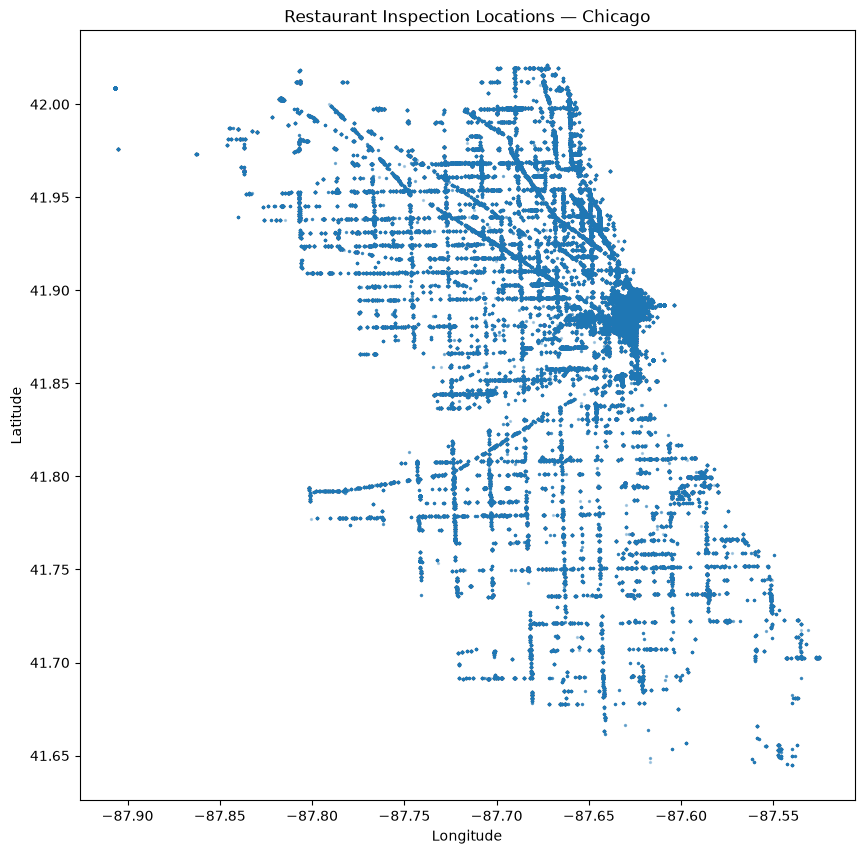

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

plt.scatter(
    geo_restaurants["Longitude"],
    geo_restaurants["Latitude"],
    s=2,
    alpha=0.3
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Restaurant Inspection Locations — Chicago")

plt.show()

Failed inspections available for mapping: 39987


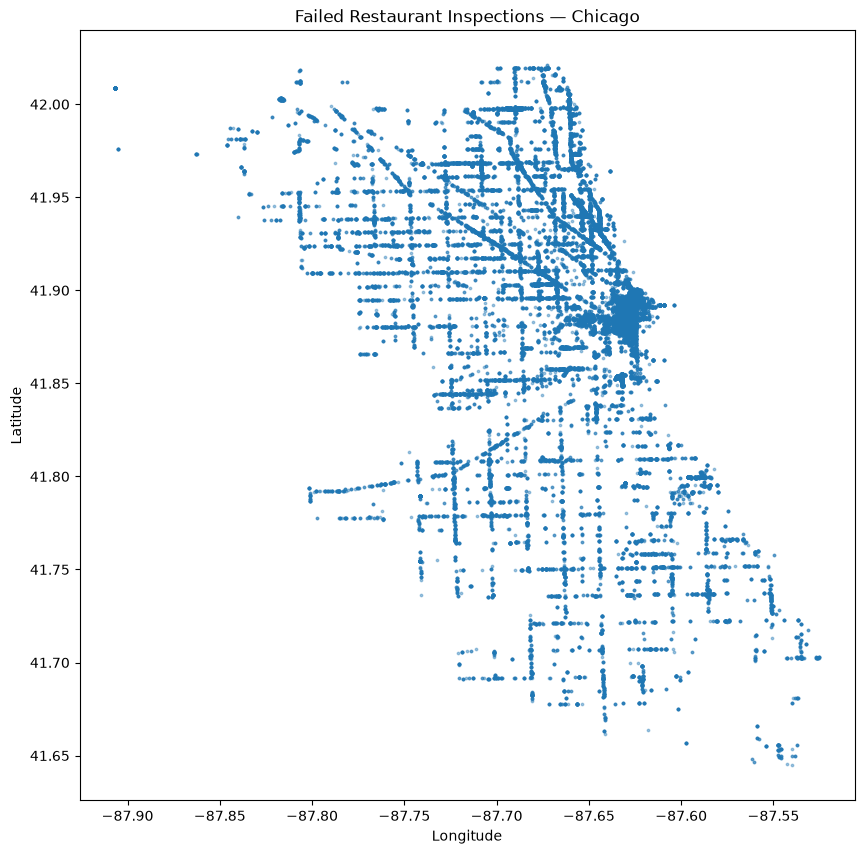

In [51]:
failed_geo = geo_restaurants[
    geo_restaurants["Results"] == "Fail"
].copy()

print("Failed inspections available for mapping:", len(failed_geo))

plt.figure(figsize=(10, 10))

plt.scatter(
    failed_geo["Longitude"],
    failed_geo["Latitude"],
    s=3,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Failed Restaurant Inspections — Chicago")

plt.show()

In [52]:
geo_restaurants["lat_grid"] = geo_restaurants["Latitude"].round(2)
geo_restaurants["lon_grid"] = geo_restaurants["Longitude"].round(2)

geo_grid_summary = (
    geo_restaurants
    .groupby(["lat_grid", "lon_grid"])
    .agg(
        total_inspections=("Inspection ID", "count"),
        failed_inspections=("Results", lambda x: (x == "Fail").sum())
    )
    .reset_index()
)

geo_grid_summary["failure_rate"] = (
    geo_grid_summary["failed_inspections"]
    / geo_grid_summary["total_inspections"]
    * 100
)

print("Number of geographic grid cells:", len(geo_grid_summary))

print("\nTop 20 grid cells by inspection count:")
print(
    geo_grid_summary
    .sort_values("total_inspections", ascending=False)
    .head(20)
)

Number of geographic grid cells: 574

Top 20 grid cells by inspection count:
     lat_grid  lon_grid  total_inspections  failed_inspections  failure_rate
354     41.89    -87.63               8566                1277     14.907775
340     41.88    -87.63               8467                1273     15.034841
355     41.89    -87.62               4968                 741     14.915459
339     41.88    -87.64               4923                 654     13.284583
372     41.90    -87.63               3833                 615     16.044873
560     42.01    -87.91               3486                 403     11.560528
450     41.94    -87.65               2940                 592     20.136054
293     41.85    -87.63               2581                 702     27.198760
338     41.88    -87.65               2564                 494     19.266771
507     41.97    -87.66               2291                 550     24.006984
428     41.93    -87.65               2240                 473     21.116071

In [53]:
reliable_geo_cells = (
    geo_grid_summary[
        geo_grid_summary["total_inspections"] >= 100
    ]
    .sort_values("failure_rate", ascending=False)
)

print(
    "Grid cells with at least 100 inspections:",
    len(reliable_geo_cells)
)

print("\nTop 20 geographic cells by failure rate:")
print(
    reliable_geo_cells[
        [
            "lat_grid",
            "lon_grid",
            "total_inspections",
            "failed_inspections",
            "failure_rate"
        ]
    ]
    .head(20)
    .round(2)
)

Grid cells with at least 100 inspections: 391

Top 20 geographic cells by failure rate:
     lat_grid  lon_grid  total_inspections  failed_inspections  failure_rate
206     41.79    -87.62                166                  57         34.34
116     41.75    -87.66                308                  92         29.87
227     41.80    -87.60                298                  87         29.19
132     41.76    -87.69                156                  45         28.85
140     41.76    -87.61                274                  79         28.83
556     42.00    -87.69               1700                 481         28.29
316     41.87    -87.70                128                  36         28.12
329     41.88    -87.74                138                  38         27.54
225     41.80    -87.62                287                  79         27.53
383     41.91    -87.72                229                  63         27.51
60      41.71    -87.61                142                  39   

In [54]:
overall_failure_rate = (
    geo_restaurants["Results"].eq("Fail").mean() * 100
)

reliable_geo_cells["failure_rate_difference"] = (
    reliable_geo_cells["failure_rate"] - overall_failure_rate
)

print(
    "Overall restaurant failure rate:",
    round(overall_failure_rate, 2),
    "%"
)

print("\nTop 20 cells above the overall failure rate:")
print(
    reliable_geo_cells[
        [
            "lat_grid",
            "lon_grid",
            "total_inspections",
            "failed_inspections",
            "failure_rate",
            "failure_rate_difference"
        ]
    ]
    .head(20)
    .round(2)
)

Overall restaurant failure rate: 18.63 %

Top 20 cells above the overall failure rate:
     lat_grid  lon_grid  total_inspections  failed_inspections  failure_rate  \
206     41.79    -87.62                166                  57         34.34   
116     41.75    -87.66                308                  92         29.87   
227     41.80    -87.60                298                  87         29.19   
132     41.76    -87.69                156                  45         28.85   
140     41.76    -87.61                274                  79         28.83   
556     42.00    -87.69               1700                 481         28.29   
316     41.87    -87.70                128                  36         28.12   
329     41.88    -87.74                138                  38         27.54   
225     41.80    -87.62                287                  79         27.53   
383     41.91    -87.72                229                  63         27.51   
60      41.71    -87.61          

In [55]:
risk_analysis = (
    restaurant_df
    .groupby("Risk", dropna=False)
    .agg(
        total_inspections=("Inspection ID", "count"),
        failed_inspections=("Results", lambda x: (x == "Fail").sum())
    )
    .reset_index()
)

risk_analysis["failure_rate"] = (
    risk_analysis["failed_inspections"]
    / risk_analysis["total_inspections"]
    * 100
)

risk_analysis = risk_analysis.sort_values(
    "failure_rate",
    ascending=False
)

risk_analysis

,Risk,total_inspections,failed_inspections,failure_rate
4,NaN,3,3,100.000000
3,Risk 3 (Low),2553,532,20.838230
1,Risk 1 (High),175700,33174,18.881047
2,Risk 2 (Medium),36573,6316,17.269570
0,All,16,1,6.250000


In [56]:
inspection_history = (
    restaurant_df
    .groupby(["License #", "Address"])
    .size()
    .rename("inspection_count")
    .reset_index()
)

print("Restaurant-location pairs:", len(inspection_history))

print("\nInspection count statistics:")
print(inspection_history["inspection_count"].describe())

print("\nInspection count distribution:")
print(
    inspection_history["inspection_count"]
    .value_counts()
    .sort_index()
    .head(20)
)

Restaurant-location pairs: 39604

Inspection count statistics:
count    39604.000000
mean         5.424806
std          5.578149
min          1.000000
25%          2.000000
50%          3.000000
75%          7.000000
max        186.000000
Name: inspection_count, dtype: float64

Inspection count distribution:
inspection_count
1     9040
2     6683
3     4785
4     3475
5     2690
6     2128
7     1565
8     1301
9     1100
10     869
11     744
12     675
13     590
14     535
15     509
16     507
17     401
18     379
19     347
20     271
Name: count, dtype: int64


In [57]:
restaurant_results = (
    restaurant_df["Results"]
    .value_counts()
    .rename_axis("Result")
    .reset_index(name="Count")
)

restaurant_results["Percentage"] = (
    restaurant_results["Count"]
    / restaurant_results["Count"].sum()
    * 100
)

restaurant_results

,Result,Count,Percentage
0,Pass,109332,50.888780
1,Fail,40026,18.630175
2,Pass w/ Conditions,35277,16.419744
3,Out of Business,15160,7.056250
4,No Entry,12011,5.590542
5,Not Ready,3009,1.400545
6,Business Not Located,30,0.013964


In [58]:
restaurant_history = restaurant_df[
    restaurant_df["License #"].notna()
].copy()

restaurant_history = restaurant_history.sort_values(
    ["License #", "Address", "Inspection Date"]
)

restaurant_history["next_result"] = (
    restaurant_history
    .groupby(["License #", "Address"])["Results"]
    .shift(-1)
)

result_transitions = (
    restaurant_history
    .dropna(subset=["next_result"])
    .groupby(["Results", "next_result"])
    .size()
    .unstack(fill_value=0)
)

result_transitions

next_result,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions
Results,,,,,,,
Business Not Located,0,0,0,1,4,7,0
Fail,0,5135,620,19,602,26631,4796
No Entry,0,1376,2208,37,1558,4775,1394
Not Ready,1,587,58,145,65,1570,481
Out of Business,0,196,102,1,292,537,220
Pass,17,15293,6210,55,8517,46231,15336
Pass w/ Conditions,5,6010,1938,12,2993,11971,7234


In [59]:
transition_percentages = (
    result_transitions
    .div(result_transitions.sum(axis=1), axis=0)
    * 100
).round(2)

transition_percentages

next_result,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions
Results,,,,,,,
Business Not Located,0.00,0.00,0.00,8.33,33.33,58.33,0.00
Fail,0.00,13.58,1.64,0.05,1.59,70.45,12.69
No Entry,0.00,12.13,19.46,0.33,13.73,42.08,12.28
Not Ready,0.03,20.19,2.00,4.99,2.24,54.01,16.55
Out of Business,0.00,14.54,7.57,0.07,21.66,39.84,16.32
Pass,0.02,16.68,6.78,0.06,9.29,50.44,16.73
Pass w/ Conditions,0.02,19.93,6.43,0.04,9.92,39.69,23.98


In [60]:
transition_percentages = (
    result_transitions
    .div(result_transitions.sum(axis=1), axis=0)
    * 100
).round(2)

transition_percentages

next_result,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions
Results,,,,,,,
Business Not Located,0.00,0.00,0.00,8.33,33.33,58.33,0.00
Fail,0.00,13.58,1.64,0.05,1.59,70.45,12.69
No Entry,0.00,12.13,19.46,0.33,13.73,42.08,12.28
Not Ready,0.03,20.19,2.00,4.99,2.24,54.01,16.55
Out of Business,0.00,14.54,7.57,0.07,21.66,39.84,16.32
Pass,0.02,16.68,6.78,0.06,9.29,50.44,16.73
Pass w/ Conditions,0.02,19.93,6.43,0.04,9.92,39.69,23.98


In [61]:
next_inspections = restaurant_history.dropna(subset=["next_result"]).copy()

next_failure_rate = (
    next_inspections["next_result"].eq("Fail").mean() * 100
)

print(f"Total previous → next inspection pairs: {len(next_inspections):,}")
print(f"Next inspections that resulted in Fail: "
      f"{next_inspections['next_result'].eq('Fail').sum():,}")
print(f"Overall next-inspection failure rate: {next_failure_rate:.2f}%")

Total previous → next inspection pairs: 175,240
Next inspections that resulted in Fail: 28,597
Overall next-inspection failure rate: 16.32%


In [63]:
restaurant_history = restaurant_df[
    restaurant_df["License #"].notna()
].copy()

restaurant_history["Inspection Date"] = pd.to_datetime(
    restaurant_history["Inspection Date"]
)

restaurant_history = restaurant_history.sort_values(
    ["License #", "Address", "Inspection Date"]
)

restaurant_history["days_since_previous"] = (
    restaurant_history
    .groupby(["License #", "Address"])["Inspection Date"]
    .diff()
    .dt.days
)

print(
    restaurant_history["days_since_previous"]
    .describe()
)

count    175240.000000
mean        300.248636
std         373.511653
min           0.000000
25%          21.000000
50%         239.000000
75%         395.000000
max        5578.000000
Name: days_since_previous, dtype: float64


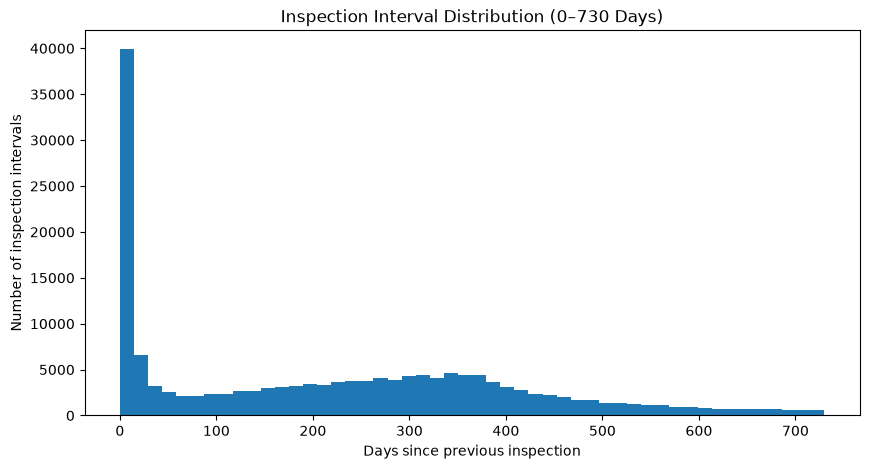

In [64]:
inspection_intervals = (
    restaurant_history["days_since_previous"]
    .dropna()
)

plt.figure(figsize=(10, 5))

plt.hist(
    inspection_intervals[inspection_intervals <= 730],
    bins=50
)

plt.xlabel("Days since previous inspection")
plt.ylabel("Number of inspection intervals")
plt.title("Inspection Interval Distribution (0–730 Days)")

plt.show()

In [65]:
restaurant_history["inspection_year"] = (
    restaurant_history["Inspection Date"].dt.year
)

yearly_inspections = (
    restaurant_history
    .groupby("inspection_year")
    .agg(
        total_inspections=("Inspection ID", "count"),
        failed_inspections=("Results", lambda x: (x == "Fail").sum())
    )
    .reset_index()
)

yearly_inspections["failure_rate"] = (
    yearly_inspections["failed_inspections"]
    / yearly_inspections["total_inspections"]
    * 100
)

yearly_inspections

,inspection_year,total_inspections,failed_inspections,failure_rate
0,2010,10727,2527,23.557379
1,2011,11238,2488,22.139171
2,2012,11312,2160,19.094767
3,2013,13933,2177,15.624776
4,2014,15046,2533,16.835039
5,2015,14326,2479,17.304202
6,2016,16184,2954,18.252595
7,2017,15352,2888,18.811881
8,2018,11842,2125,17.944604
9,2019,13507,2458,18.197971


In [66]:
next_result_distribution = (
    next_inspections["next_result"]
    .value_counts()
    .rename_axis("Next Result")
    .reset_index(name="Count")
)

next_result_distribution["Percentage"] = (
    next_result_distribution["Count"]
    / next_result_distribution["Count"].sum()
    * 100
)

next_result_distribution

,Next Result,Count,Percentage
0,Pass,91722,52.340790
1,Pass w/ Conditions,29461,16.811801
2,Fail,28597,16.318763
3,Out of Business,14031,8.006734
4,No Entry,11136,6.354714
5,Not Ready,270,0.154074
6,Business Not Located,23,0.013125


In [67]:
target_comparison = pd.DataFrame({
    "Target Definition": [
        "Strict Pass vs Fail",
        "Fail vs Pass/Conditional",
    ],
    "Positive (Fail)": [
        (next_inspections["next_result"] == "Fail").sum(),
        (next_inspections["next_result"] == "Fail").sum()
    ],
    "Negative": [
        (next_inspections["next_result"] == "Pass").sum(),
        next_inspections["next_result"].isin(
            ["Pass", "Pass w/ Conditions"]
        ).sum()
    ]
})

target_comparison["Usable Pairs"] = (
    target_comparison["Positive (Fail)"]
    + target_comparison["Negative"]
)

target_comparison["Failure Rate"] = (
    target_comparison["Positive (Fail)"]
    / target_comparison["Usable Pairs"]
    * 100
)

target_comparison

,Target Definition,Positive (Fail),Negative,Usable Pairs,Failure Rate
0,Strict Pass vs Fail,28597,91722,120319,23.767651
1,Fail vs Pass/Conditional,28597,121183,149780,19.092669


In [69]:
print(restaurant_history.columns.tolist())

['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type', 'Risk', 'Address', 'City', 'State', 'Zip', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Latitude', 'Longitude', 'Location', 'days_since_previous', 'inspection_year']


In [70]:
restaurant_history["next_result"] = (
    restaurant_history
    .groupby(["License #", "Address"])["Results"]
    .shift(-1)
)

In [71]:
print(restaurant_history["next_result"].value_counts(dropna=False))

next_result
Pass                    91722
NaN                     39604
Pass w/ Conditions      29461
Fail                    28597
Out of Business         14031
No Entry                11136
Not Ready                 270
Business Not Located       23
Name: count, dtype: int64


In [72]:
next_result_distribution = (
    restaurant_history["next_result"]
    .dropna()
    .value_counts()
    .to_frame("count")
)

next_result_distribution["percentage"] = (
    next_result_distribution["count"]
    / next_result_distribution["count"].sum()
    * 100
)

next_result_distribution

,count,percentage
next_result,,
Pass,91722,52.340790
Pass w/ Conditions,29461,16.811801
Fail,28597,16.318763
Out of Business,14031,8.006734
No Entry,11136,6.354714
Not Ready,270,0.154074
Business Not Located,23,0.013125
